<a href="https://colab.research.google.com/github/mariemembengue720-tech/PAC-Learning/blob/main/Homework1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

NOM : MBENGUE

PRENOM : Marieme

CLASSE: M2 IMDS

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Pour la reproductibilité
np.random.seed(42)



Étape 1 : Génération des donnéesOn définit :L'espace d'entrée $\mathcal{X} = [0, 1]$.

Le vrai seuil cible $\theta^* \in (0, 1)$.

La fonction cible $f_{\theta^*}(x) = 1$ si $x > \theta^*$, sinon $0$.

In [ ]:
def generate_data(m, theta_star=0.4, noise_rate=0.0):
    """
    Génère m exemples uniformément répartis sur [0, 1].
    - noise_rate = 0.0 -> Cadre Réalisable
    - noise_rate > 0.0 -> Cadre Agnostique (avec bruit)
    """
    X = np.random.uniform(0, 1, m)

    # Étiquettes parfaites (Réalisable)
    y = (X > theta_star).astype(int)

    # Ajout de bruit sur les étiquettes (Agnostique)
    if noise_rate > 0.0:
        # On choisit aléatoirement les indices à inverser avec une probabilité noise_rate
        flip_mask = np.random.rand(m) < noise_rate
        y[flip_mask] = 1 - y[flip_mask]  # Inverse 0 en 1 et 1 en 0

    return X, y

Étape 2 : Implémentation de l'ERM (Minimisation du Risque Empirique)Stratégie pour trouver le seuil optimal $\hat{\theta}$ :Puisque tous les classifieurs possibles sont de la forme $h_\theta(x) = \mathbb{I}(x > \theta)$, les seuls seuils $\theta$ qui modifient les prédictions sur un échantillon donné $S = \{(x_1, y_1), \dots, (x_m, y_m)\}$ sont les points $x_i$ eux-mêmes (ou les milieux entre deux points successifs triés).

On trie les points $x_i$.On teste comme seuils candidats : $0$, les milieux entre chaque paire de points consécutifs, et $1$.

Pour chaque candidat $\theta$, on calcule l'erreur empirique $L_S(h_\theta) = \frac{1}{m} \sum_{i=1}^m \mathbb{I}(h_\theta(x_i) \neq y_i)$.On retient le $\hat{\theta}$ qui minimise cette erreur empirique.

In [ ]:
def fit_erm_threshold(X, y):
    """
    Trouve le seuil theta_hat qui minimise l'erreur empirique sur (X, y).
    """
    m = len(X)
    sorted_indices = np.argsort(X)
    X_sorted = X[sorted_indices]
    y_sorted = y[sorted_indices]

    # Candidats pour le seuil theta : 0, milieux des points adjacents, et 1
    candidates = [0.0]
    for i in range(m - 1):
        candidates.append((X_sorted[i] + X_sorted[i+1]) / 2.0)
    candidates.append(1.0)

    best_theta = 0.5
    min_error = float('inf')

    for cand in candidates:
        # Prédiction avec le seuil candidat
        preds = (X > cand).astype(int)
        # Calcul de l'erreur empirique
        err = np.mean(preds != y)

        if err < min_error:
            min_error = err
            best_theta = cand

    return best_theta, min_error

Étape 3 : Évaluation des performances ($L_S$ vs $L_D$)

Pour calculer l'erreur réelle $L_D(h_{\hat{\theta}})$, on génère un grand jeu de test indépendant (par exemple $m_{test} = 10\,000$ points) sans bruit (puisque l'erreur réelle mesure l'écart par rapport à la vraie distribution sous-jacente $f_{\theta^*}$).

In [ ]:
def compute_true_error(theta_hat, theta_star=0.4, n_test=10000):
    """
    Calcule l'erreur réelle L_D(h) sur un grand jeu de test indépendant.
    En dimension 1 avec distribution uniforme, L_D(h) est aussi égal à |theta_hat - theta_star|.
    """
    X_test = np.random.uniform(0, 1, n_test)
    y_test = (X_test > theta_star).astype(int)

    preds_test = (X_test > theta_hat).astype(int)
    return np.mean(preds_test != y_test)

# Test rapide pour un jeu d'entraînement de taille m = 20
X_train, y_train = generate_data(m=20, theta_star=0.4, noise_rate=0.0)
theta_hat, L_S = fit_erm_threshold(X_train, y_train)
L_D = compute_true_error(theta_hat, theta_star=0.4)

print(f"Seuil estimé (theta_hat) : {theta_hat:.3f}")
print(f"Erreur empirique (L_S)  : {L_S:.4f}")
print(f"Erreur réelle (L_D)     : {L_D:.4f}")

Seuil estimé (theta_hat) : 0.403
Erreur empirique (L_S)  : 0.0000
Erreur réelle (L_D)     : 0.0035


Étape 4 : Vérification expérimentale de l'apprentissage PAC (Cadre Réalisable)
Ici, on fixe $\varepsilon = 0,1$ et on fait tourner $N = 1000$ simulations pour chaque taille d'échantillon $m \in \{5, 10, 20, 50, 100, 200\}$. On compte la proportion de fois où l'erreur réelle $L_D(h_{\hat{\theta}})$ dépasse $\varepsilon$, ce qui nous donne une estimation de $\Pr(L_D(h) > \varepsilon)$.

m =   5 | P(L_D > 0.1) = 0.3330
m =  10 | P(L_D > 0.1) = 0.1040
m =  20 | P(L_D > 0.1) = 0.0140
m =  50 | P(L_D > 0.1) = 0.0000
m = 100 | P(L_D > 0.1) = 0.0000
m = 200 | P(L_D > 0.1) = 0.0000


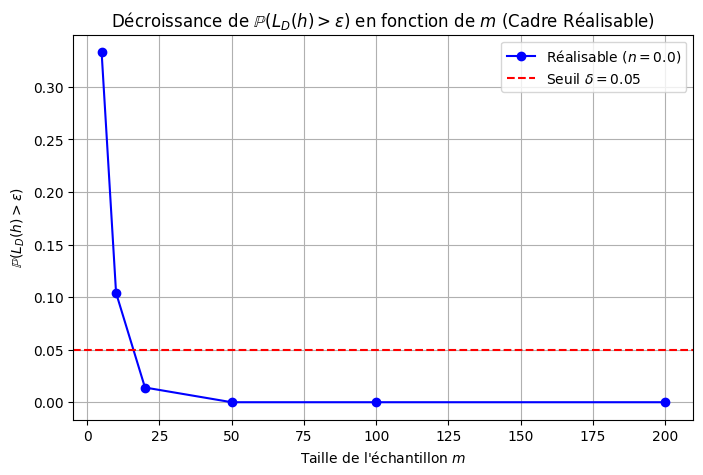

In [ ]:
def experiment_pac_realizable(sample_sizes, epsilon=0.1, n_reps=1000, theta_star=0.4):
    probs_bad_generalization = []

    for m in sample_sizes:
        bad_count = 0
        for _ in range(n_reps):
            X_train, y_train = generate_data(m=m, theta_star=theta_star, noise_rate=0.0)
            theta_hat, _ = fit_erm_threshold(X_train, y_train)
            L_D = compute_true_error(theta_hat, theta_star=theta_star)

            if L_D > epsilon:
                bad_count += 1

        prob = bad_count / n_reps
        probs_bad_generalization.append(prob)
        print(f"m = {m:3d} | P(L_D > {epsilon}) = {prob:.4f}")

    return probs_bad_generalization

sample_sizes = [5, 10, 20, 50, 100, 200]
probs_realizable = experiment_pac_realizable(sample_sizes, epsilon=0.1, n_reps=1000)

# Tracé de la courbe pour le cas réalisable
plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, probs_realizable, 'o-', color='blue', label=r'Réalisable ($n = 0.0$)')
plt.axhline(y=0.05, color='r', linestyle='--', label=r'Seuil $\delta = 0.05$')
plt.xlabel("Taille de l'échantillon $m$")
plt.ylabel(r"$\mathbb{P}(L_D(h) > \epsilon)$")
plt.title(r"Décroissance de $\mathbb{P}(L_D(h) > \epsilon)$ en fonction de $m$ (Cadre Réalisable)")
plt.grid(True)
plt.legend()
plt.show()

Du PAC au PAC AgnostiqueOn introduit maintenant un taux de bruit $n = 0,15$ (15 % d'étiquettes inversées de manière aléatoire) pour observer le comportement de l'ERM dans le cadre agnostique.

m =   5 (Agnostique) | P(L_D > 0.1) = 0.5240
m =  10 (Agnostique) | P(L_D > 0.1) = 0.3790
m =  20 (Agnostique) | P(L_D > 0.1) = 0.2220
m =  50 (Agnostique) | P(L_D > 0.1) = 0.0470
m = 100 (Agnostique) | P(L_D > 0.1) = 0.0090
m = 200 (Agnostique) | P(L_D > 0.1) = 0.0000


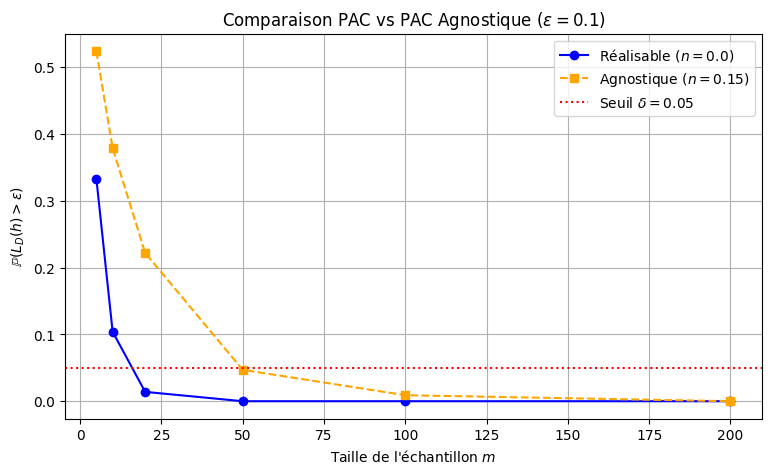

In [ ]:
def experiment_pac_agnostic(sample_sizes, epsilon=0.1, noise_rate=0.15, n_reps=1000, theta_star=0.4):
    probs_bad_generalization = []

    for m in sample_sizes:
        bad_count = 0
        for _ in range(n_reps):
            # Génération avec du bruit de label
            X_train, y_train = generate_data(m=m, theta_star=theta_star, noise_rate=noise_rate)
            theta_hat, _ = fit_erm_threshold(X_train, y_train)

            # L_D est calculé par rapport à la vraie distribution sous-jacente (sans bruit)
            L_D = compute_true_error(theta_hat, theta_star=theta_star)

            if L_D > epsilon:
                bad_count += 1

        prob = bad_count / n_reps
        probs_bad_generalization.append(prob)
        print(f"m = {m:3d} (Agnostique) | P(L_D > {epsilon}) = {prob:.4f}")

    return probs_bad_generalization

# Lancement des simulations agnostiques
probs_agnostic = experiment_pac_agnostic(sample_sizes, epsilon=0.1, noise_rate=0.15, n_reps=1000)

# Comparaison des deux cadres (Réalisable vs Agnostique)
plt.figure(figsize=(9, 5))
plt.plot(sample_sizes, probs_realizable, 'o-', color='blue', label=r'Réalisable ($n = 0.0$)')
plt.plot(sample_sizes, probs_agnostic, 's--', color='orange', label=r'Agnostique ($n = 0.15$)')
plt.axhline(y=0.05, color='r', linestyle=':', label=r'Seuil $\delta = 0.05$')
plt.xlabel("Taille de l'échantillon $m$")
plt.ylabel(r"$\mathbb{P}(L_D(h) > \epsilon)$")
plt.title(r"Comparaison PAC vs PAC Agnostique ($\epsilon = 0.1$)")
plt.grid(True)
plt.legend()
plt.show()

## 6. Analyse et Conclusion : Du PAC au PAC Agnostique

### Réponses aux questions de réflexion :

1. **L'erreur empirique $L_S(h)$ peut-elle toujours atteindre zéro ?**
   - **Cadre Réalisable ($n = 0.0$) :** Oui. Comme les données sont générées directement par la fonction cible $f_{\theta^*}(x)$ sans perturbation, il existe une hypothèse parfaite $h^* \in \mathcal{H}$ telle que $L_S(h^*) = 0$.
   - **Cadre Agnostique ($n = 0.15$) :** Non. L'introduction du bruit sur les étiquettes crée des incohérences dans les données d'entraînement. L'erreur empirique minimale $L_S(\hat{\theta})$ reste généralement supérieure à zéro et converge vers le taux de bruit $n$.

2. **L'augmentation du nombre d'exemples $m$ améliore-t-elle toujours la performance de généralisation ?**
   - Oui, dans les deux cas, la hausse de $m$ permet de réduire la probabilité de mauvaise généralisation $\mathbb{P}(L_D(h) > \varepsilon)$. Cependant, la vitesse de convergence diffère grandement :
     - En **PAC Réalisable**, la convergence est très rapide (dépendance en $\mathcal{O}(1/\varepsilon)$).
     - En **PAC Agnostique**, la convergence est beaucoup plus lente (dépendance en $\mathcal{O}(1/\varepsilon^2)$) car l'algorithme a besoin de plus d'échantillons pour moyenner et filtrer l'impact du bruit aléatoire.

3. **Lien avec les concepts du cours :**
   - Dans le **cadre PAC**, on suppose que la distribution sous-jacente est parfaitement représentable par un modèle de notre classe d'hypothèses ($L_D(h^*) = 0$).
   - Dans le **cadre PAC Agnostique**, on renonce à cette hypothèse de réalisabilité. On cherche simplement l'hypothèse de $\mathcal{H}$ qui se rapproche le plus de la meilleure hypothèse théorique possible ($L_D(h_S) \le L_D(h^*) + \varepsilon$).

### Conclusion
Les résultats expérimentaux confirment la théorie : l'absence d'hypothèse de réalisabilité nécessite une taille d'échantillon $m$ significativement plus importante pour garantir le même niveau de précision $\varepsilon$ et de confiance $1 - \delta$.